In [1]:
from tavi.library.Instrument.instrument import Instrument, InstrumentCatalog
from tavi.library.experiment.experiment import Experiment
from tavi.library.experiment.utilities import mantid_to_spice
from tavi.library.tas.triple_axis import TAS
from tavi.library.fit import ModelName
from pathlib import Path
import numpy as np


# Set up for Hb3. 
The spice_ub is read from a .ini file from UBConf. Sample mosaic can be tuned mannually. Lattice information would need to be input by hand.

In [2]:
from tavi.library.experiment.utilities import spice_to_mantid
from tavi.library.geometry.oriented_lattice import OrientedLattice
from tavi.library.geometry.sample import Sample

experiment = Experiment()
ol = OrientedLattice(a=4.938669, b =4.938669, c = 13.592861, alpha=90, beta = 90, gamma = 120)
spice_ub = np.array([[-0.144255,-0.072128,-0.057896],
                     [0.184002,0.092001,-0.045390],
                     [0.000000,-0.202484,-0.000000]])
ol.UB = spice_to_mantid(spice_ub, version="old")
sample = Sample(ol)
sample.mosaic_h = 35
sample.mosaic_v = 35
tas = TAS(Instrument(instrument_catalog=InstrumentCatalog.HB3), sample, experiment)
datafiles = Path.cwd().parent.joinpath("test_data","IPTS-37534", "exp871", "Datafiles")
tas.experiment.load_folder(datafiles)

# Browse several inelastic scans.

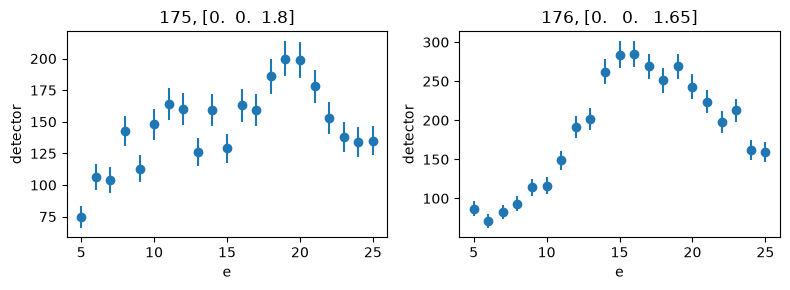

(None, None, None)

In [3]:
scan_list = list([175,176])
tas.browse(scan_list, show_fits = False)

In [4]:
def get_uuid_from_scan_list(experiment, scan_list, IPTS=None, exp_num=None):
    """Resolve SPICE scan numbers to the uuids a ProcessOps takes, in the order given."""
    return [
        experiment.get_data_from_scan_number({"scan_num": scan_num, "IPTS": IPTS, "exp_num": exp_num}).uuid
        for scan_num in scan_list
    ]

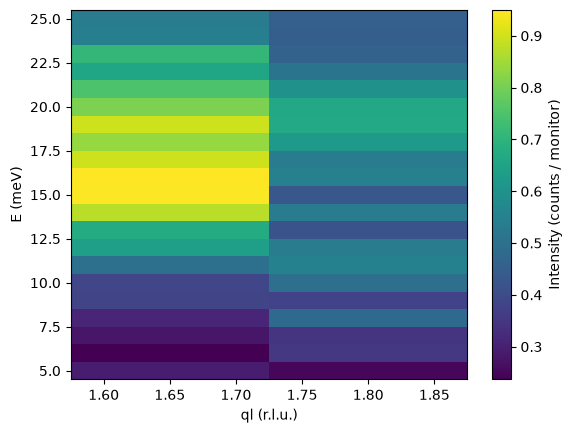

In [9]:
append_list = [175, 176]
tavi_data = tas.experiment.tavi_data
scan_list_uuids = get_uuid_from_scan_list(experiment=tas.experiment, scan_list=append_list)
from tavi.library.data.algorithms.histogram import Histogram
from matplotlib import pyplot as plt   

r = Histogram(tavi_data=tavi_data, uuids=scan_list_uuids, columns=["l", "e", "detector", "mcu"]).exec()

fig, ax = plt.subplots()
mesh = ax.pcolormesh(r.x_edges, r.y_edges, r.intensity.T, shading="flat")
fig.colorbar(mesh, ax=ax, label="Intensity (counts / monitor)")
ax.set_xlabel("ql (r.l.u.)")
ax.set_ylabel("E (meV)")
plt.show()

In [10]:
print(r.x_edges)
print(r.y_centers)

[1.575 1.725 1.875]
[ 5.00045  6.0003   7.00035  8.0003   9.0003  10.0003  11.00045 12.00015
 13.0005  14.0004  15.0004  16.00045 17.0001  18.00045 18.99995 20.0002
 20.99995 22.00075 23.00015 24.0004  25.00245]
